# Sentiment Visualizations — Reel Variance

Visualizations of `Data/IMDB_reviews_with_sentiment.json` (output of `NLP_Analysis.ipynb`).

- `sentiment_score` — DistilBERT score on the review **summary**, -1 to +1
- `review_sentiment_score` — DistilBERT score on the **full review text**, -1 to +1

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, PowerNorm, TwoSlopeNorm

TEAL, AMBER, CORAL, SLATE, GREY = '#2a9d8f', '#e9c46a', '#e76f51', '#577590', '#8a8f98'
SEQ = LinearSegmentedColormap.from_list('seq', ['#f1f5f8', SLATE, '#1d3557'])

plt.rcParams.update({
    'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'axes.titleweight': 'bold',
    'axes.titlesize': 12, 'axes.titlelocation': 'left',
})

## Load data

In [2]:
DATA_FILE = 'Data/IMDB_reviews_with_sentiment.json'   # ~1 GB: read in chunks, drop review_text to save memory

parts = []
for chunk in pd.read_json(DATA_FILE, lines=True, chunksize=50_000):
    chunk['review_words'] = chunk['review_text'].fillna('').str.split().str.len()
    parts.append(chunk.drop(columns='review_text'))
df = pd.concat(parts, ignore_index=True)
del parts

df['review_date'] = pd.to_datetime(df['review_date'], errors='coerce', format='mixed')
df['year'] = df['review_date'].dt.year

# movie metadata (genres) + titles
movies = pd.read_json('Data/IMDB_Spoilers_DataSet/IMDB_movie_details.json', lines=True)[['movie_id', 'genre', 'release_date']]
titles = (pd.read_csv('Data/Additional_Film_Data/movies_metadata.csv', low_memory=False, usecols=['imdb_id', 'title'])
            .dropna().drop_duplicates('imdb_id').rename(columns={'imdb_id': 'movie_id'}))
movies = movies.merge(titles, on='movie_id', how='left')
movies['title'] = movies['title'].fillna(movies['movie_id'])
df = df.merge(movies, on='movie_id', how='left')

print(f'{len(df):,} reviews, {df.movie_id.nunique():,} movies')
df.head()

573,913 reviews, 1,572 movies


,movie_id,user_id,review_date,rating,is_spoiler,review_summary,sentiment_label,sentiment_score,review_sentiment_label,review_sentiment_score,review_words,year,genre,release_date,title
0,tt0111161,ur1898687,2006-02-10,10,True,A classic piece of unforgettable film-making.,POSITIVE,0.9999,POSITIVE,0.9960,843,2006,"[Crime, Drama]",1994-10-14,The Shawshank Redemption
1,tt0111161,ur0842118,2000-09-06,10,True,Simply amazing. The best film of the 90's.,POSITIVE,0.9999,POSITIVE,0.9995,223,2000,"[Crime, Drama]",1994-10-14,The Shawshank Redemption
2,tt0111161,ur1285640,2001-08-03,8,True,The best story ever told on film,POSITIVE,0.9998,POSITIVE,0.9993,250,2001,"[Crime, Drama]",1994-10-14,The Shawshank Redemption
3,tt0111161,ur1003471,2002-09-01,10,True,Busy dying or busy living?,NEGATIVE,-0.9987,POSITIVE,0.9601,741,2002,"[Crime, Drama]",1994-10-14,The Shawshank Redemption
4,tt0111161,ur0226855,2004-05-20,8,True,"Great story, wondrously told and acted",POSITIVE,0.9999,POSITIVE,0.9980,829,2004,"[Crime, Drama]",1994-10-14,The Shawshank Redemption


## 1. Overall: full-text sentiment vs star rating

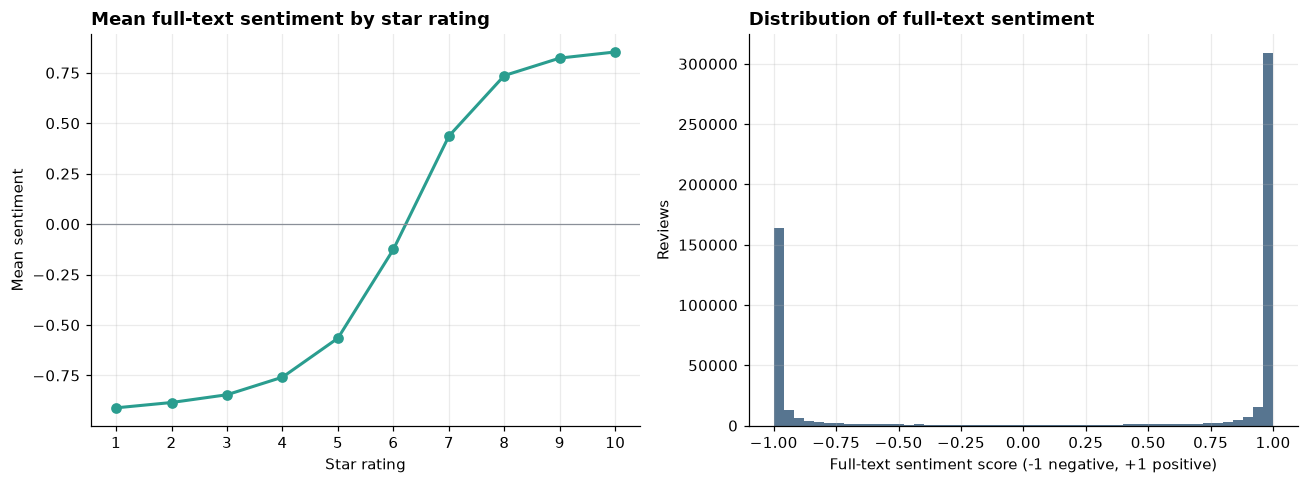

In [3]:
by_rating = df.groupby('rating')['review_sentiment_score'].mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(by_rating.index, by_rating.values, marker='o', color=TEAL, lw=2)
axes[0].axhline(0, color=GREY, lw=0.8)
axes[0].set_xticks(range(1, 11))
axes[0].set_xlabel('Star rating'); axes[0].set_ylabel('Mean sentiment')
axes[0].set_title('Mean full-text sentiment by star rating')

axes[1].hist(df['review_sentiment_score'], bins=50, color=SLATE)
axes[1].set_xlabel('Full-text sentiment score (-1 negative, +1 positive)'); axes[1].set_ylabel('Reviews')
axes[1].set_title('Distribution of full-text sentiment')
plt.tight_layout(); plt.show()

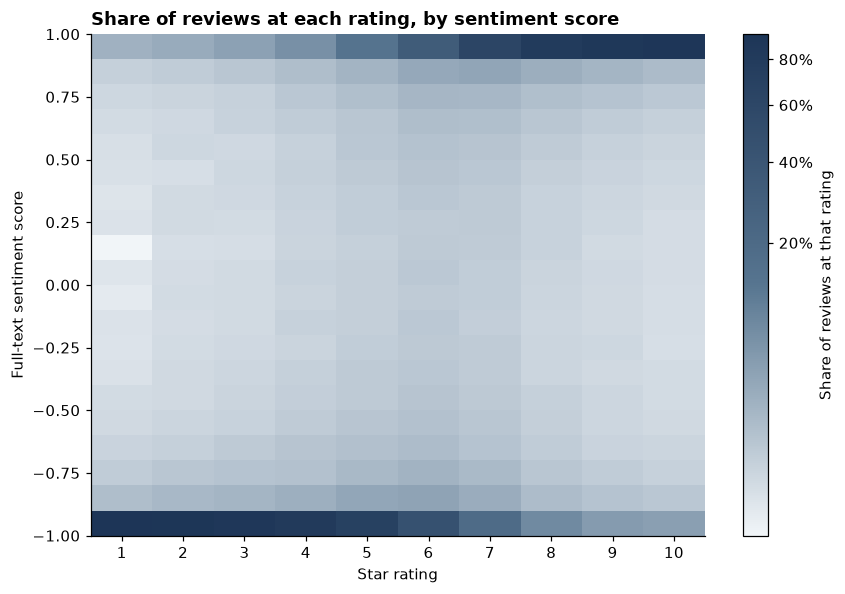

In [4]:
bins = np.linspace(-1, 1, 21)
df['sent_bin'] = pd.cut(df['review_sentiment_score'], bins, include_lowest=True)
heat = pd.crosstab(df['sent_bin'], df['rating'], normalize='columns').sort_index(ascending=False)

fig, ax = plt.subplots(figsize=(8, 5.5))
im = ax.imshow(heat.values, aspect='auto', cmap=SEQ, norm=PowerNorm(0.35), extent=[0.5, 10.5, -1, 1])  # power norm keeps the middle bins visible
ax.grid(False); ax.set_xticks(range(1, 11))
ax.set_xlabel('Star rating'); ax.set_ylabel('Full-text sentiment score')
ax.set_title('Share of reviews at each rating, by sentiment score')
fig.colorbar(im, ax=ax, label='Share of reviews at that rating', format='{x:.0%}')
plt.tight_layout(); plt.show()

## 2. Across genres

A review counts toward every genre its movie is tagged with, so one review can appear in several genres.

In [5]:
MIN_GENRE_REVIEWS = 2000

g = df.explode('genre').dropna(subset=['genre']).copy()
g['pos'] = g['review_sentiment_score'] > 0.5
g['neg'] = g['review_sentiment_score'] < -0.5
g['mixed'] = ~(g['pos'] | g['neg'])

gstats = (g.groupby('genre')
            .agg(reviews=('rating', 'size'), movies=('movie_id', 'nunique'),
                 mean_sent=('review_sentiment_score', 'mean'), sent_std=('review_sentiment_score', 'std'),
                 mean_rating=('rating', 'mean'), pos=('pos', 'mean'), neg=('neg', 'mean'), mixed=('mixed', 'mean'))
            .query('reviews >= @MIN_GENRE_REVIEWS')
            .sort_values('mean_sent'))
GENRES = gstats.index.tolist()          # fixed order (lowest -> highest sentiment) reused by every chart below
g = g[g['genre'].isin(GENRES)]
gstats.round(3)

,reviews,movies,mean_sent,sent_std,mean_rating,pos,neg,mixed
genre,,,,,,,,
Sci-Fi,95550,188,0.074,0.953,6.388,0.518,0.444,0.038
Horror,46784,116,0.108,0.946,6.435,0.534,0.424,0.043
Action,190717,438,0.132,0.947,6.480,0.547,0.415,0.038
Fantasy,77098,178,0.171,0.943,6.692,0.567,0.396,0.037
Adventure,187293,433,0.182,0.941,6.686,0.573,0.391,0.036
Mystery,64051,161,0.192,0.936,6.829,0.577,0.384,0.039
Thriller,95221,232,0.194,0.935,6.750,0.578,0.382,0.040
Family,39559,155,0.299,0.914,6.968,0.633,0.333,0.034
Comedy,135968,524,0.327,0.904,6.956,0.648,0.318,0.034


### Mean sentiment by genre

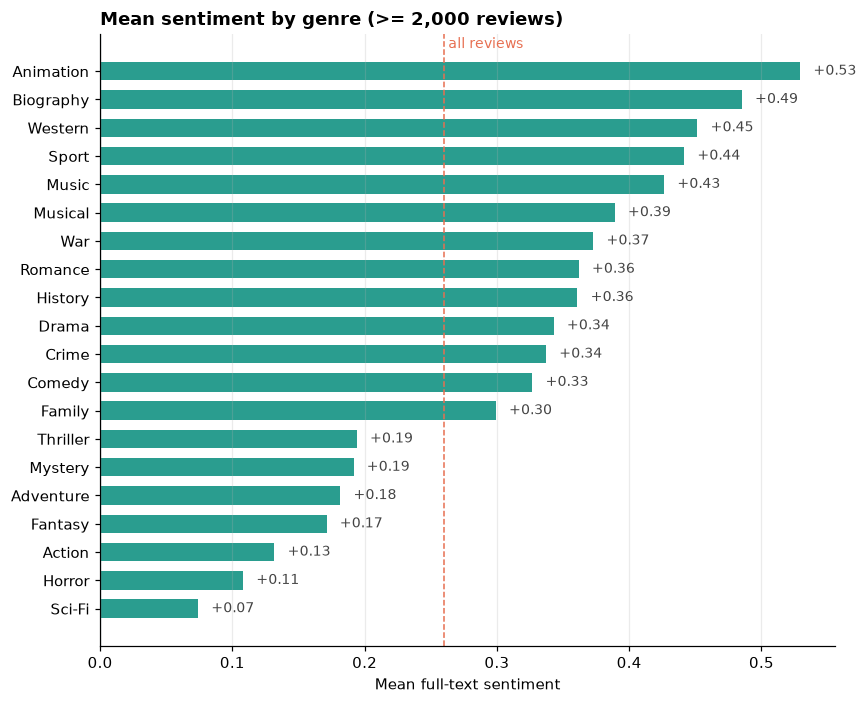

In [6]:
fig, ax = plt.subplots(figsize=(8, 6.5))
bars = ax.barh(gstats.index, gstats['mean_sent'], color=TEAL, height=0.65)
for y, (v, n) in enumerate(zip(gstats['mean_sent'], gstats['reviews'])):
    ax.text(v + (0.01 if v >= 0 else -0.01), y, f'{v:+.2f}', va='center', ha='left' if v >= 0 else 'right', fontsize=9, color='#444')
ax.axvline(0, color=GREY, lw=0.8)
ax.axvline(df['review_sentiment_score'].mean(), color=CORAL, lw=1, ls='--')
ax.text(df['review_sentiment_score'].mean(), len(gstats) - 0.3, ' all reviews', color=CORAL, fontsize=9, va='bottom')
ax.grid(axis='y', visible=False)
ax.set_xlabel('Mean full-text sentiment'); ax.set_title(f'Mean sentiment by genre (>= {MIN_GENRE_REVIEWS:,} reviews)')
plt.tight_layout(); plt.show()

### Positive / mixed / negative split by genre

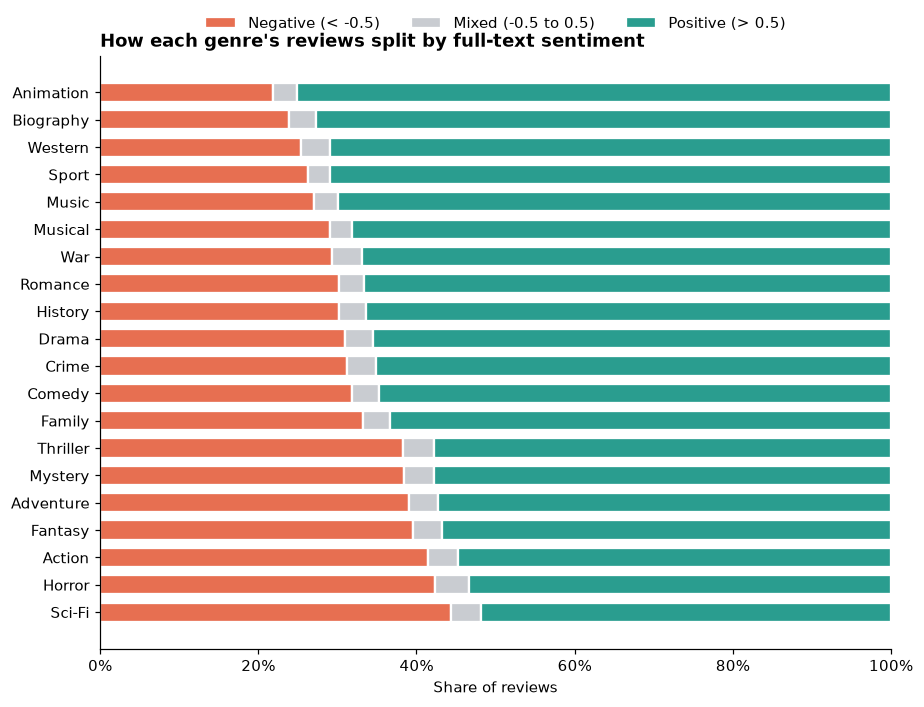

In [7]:
fig, ax = plt.subplots(figsize=(8.5, 6.5))
left = np.zeros(len(gstats))
for col, label, color in [('neg', 'Negative (< -0.5)', CORAL), ('mixed', 'Mixed (-0.5 to 0.5)', '#c9ccd1'), ('pos', 'Positive (> 0.5)', TEAL)]:
    ax.barh(gstats.index, gstats[col], left=left, color=color, label=label, height=0.7, edgecolor='white', linewidth=1.5)
    left += gstats[col].values
ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(lambda x, _: f'{x:.0%}')
ax.grid(False)
ax.set_xlabel('Share of reviews'); ax.set_title('How each genre\'s reviews split by full-text sentiment')
ax.legend(ncol=3, frameon=False, loc='upper center', bbox_to_anchor=(0.5, 1.09))
plt.tight_layout(); plt.show()

### Do genre reviews read harsher or kinder than their star ratings imply?

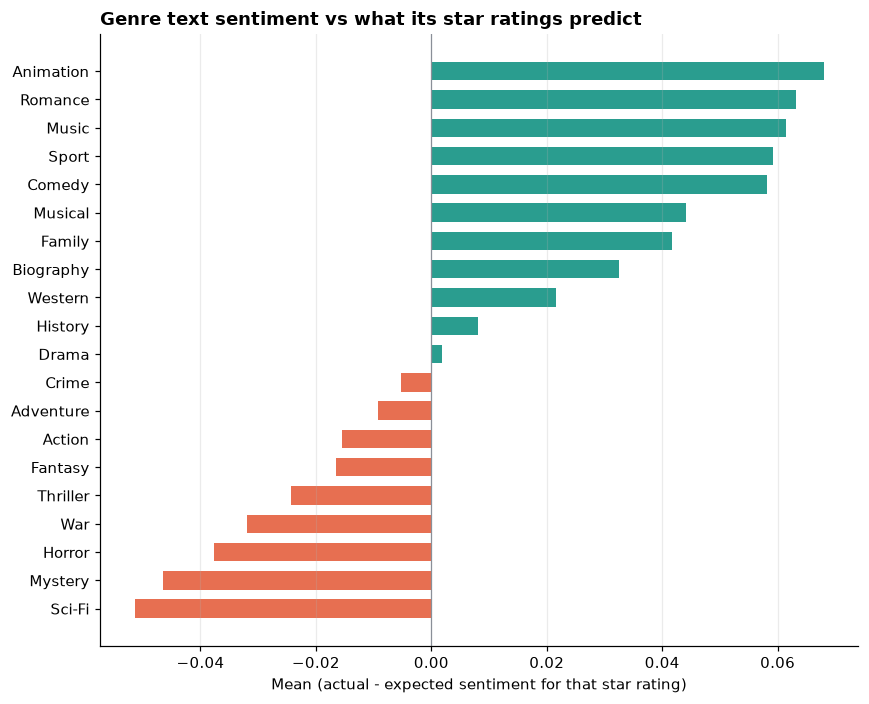

In [8]:
# Expected sentiment given only the star rating, then how far each genre's reviews sit from it.
expected = g.groupby('rating')['review_sentiment_score'].transform('mean')
g['resid'] = g['review_sentiment_score'] - expected
resid = g.groupby('genre')['resid'].mean().reindex(GENRES).sort_values()

fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(resid.index, resid.values, color=np.where(resid.values >= 0, TEAL, CORAL), height=0.65)
ax.axvline(0, color=GREY, lw=0.8); ax.grid(axis='y', visible=False)
ax.set_xlabel('Mean (actual - expected sentiment for that star rating)')
ax.set_title('Genre text sentiment vs what its star ratings predict')
plt.tight_layout(); plt.show()

### Average star rating vs average sentiment, by genre

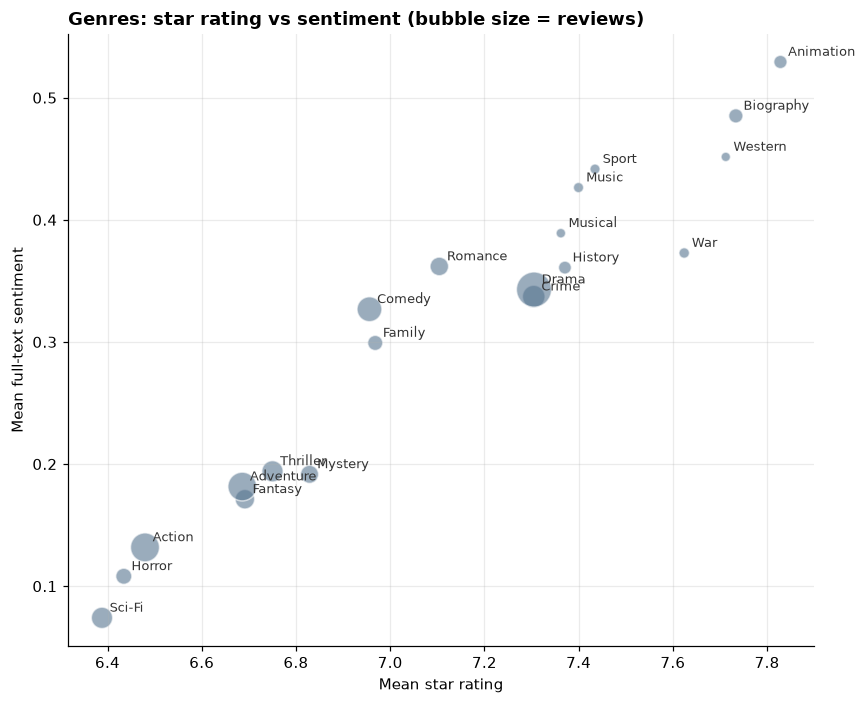

In [9]:
fig, ax = plt.subplots(figsize=(8, 6.5))
ax.scatter(gstats['mean_rating'], gstats['mean_sent'], s=gstats['reviews'] / gstats['reviews'].max() * 500 + 30, color=SLATE, alpha=0.6, edgecolor='white')
for name, r in gstats.iterrows():
    ax.annotate(name, (r['mean_rating'], r['mean_sent']), xytext=(5, 4), textcoords='offset points', fontsize=8.5, color='#333')
ax.set_xlabel('Mean star rating'); ax.set_ylabel('Mean full-text sentiment')
ax.set_title('Genres: star rating vs sentiment (bubble size = reviews)')
plt.tight_layout(); plt.show()

### Variance within each genre

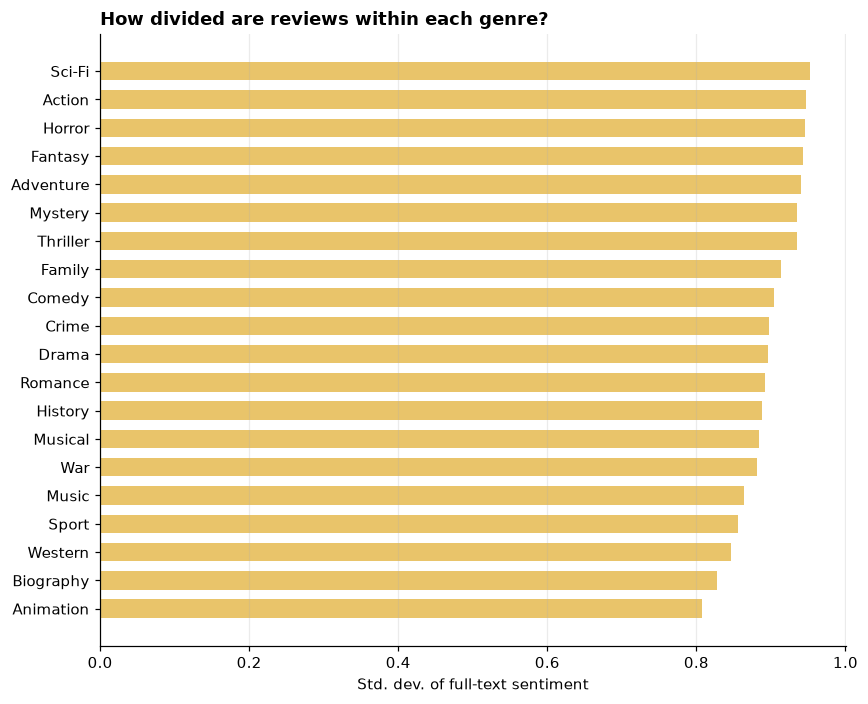

In [10]:
v = gstats.sort_values('sent_std')
fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(v.index, v['sent_std'], color=AMBER, height=0.65)
ax.grid(axis='y', visible=False)
ax.set_xlabel('Std. dev. of full-text sentiment'); ax.set_title('How divided are reviews within each genre?')
plt.tight_layout(); plt.show()

### Genre by review year

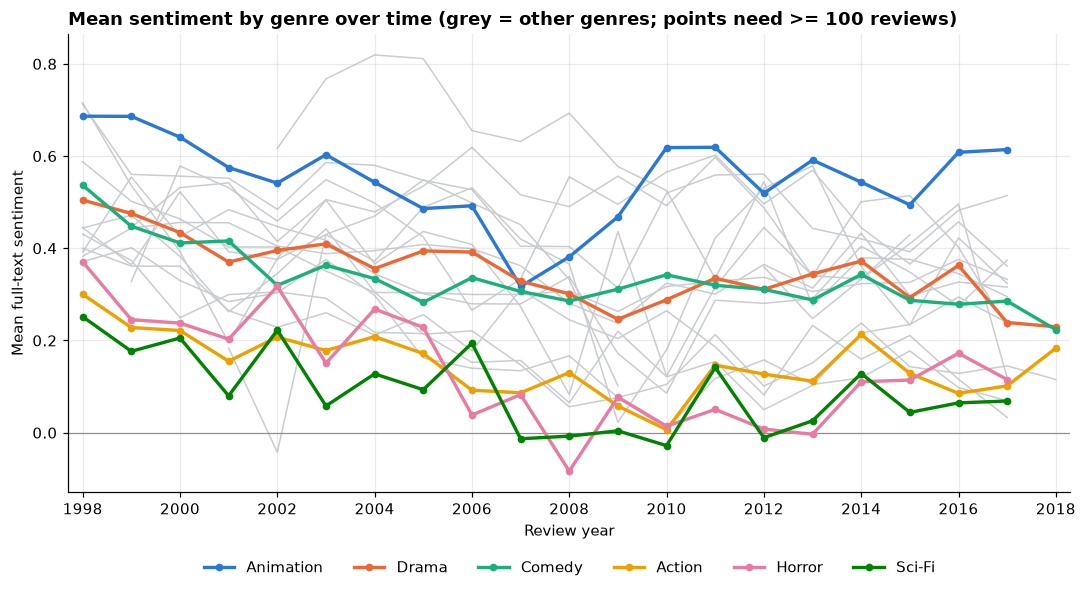

In [11]:
HIGHLIGHT = ['Animation', 'Drama', 'Comedy', 'Action', 'Horror', 'Sci-Fi']   # up to 6-8; edit freely
COLORS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300']  # fixed order, one per highlighted genre
MIN_POINT = 100                                                              # hide yearly points with fewer reviews

gy = (g[g['year'].between(1998, 2018)]
        .groupby(['genre', 'year'])['review_sentiment_score'].agg(['mean', 'size']).reset_index())
gy = gy[gy['size'] >= MIN_POINT]
lines = gy.pivot(index='year', columns='genre', values='mean')

fig, ax = plt.subplots(figsize=(10, 5.5))
for genre in lines.columns.difference(HIGHLIGHT):                 # context: every other genre in light grey
    ax.plot(lines.index, lines[genre], color='#c9ccd1', lw=1, zorder=1)
for genre, color in zip(HIGHLIGHT, COLORS):
    s = lines[genre].dropna()
    ax.plot(s.index, s.values, color=color, lw=2.2, marker='o', ms=4, label=genre, zorder=3)
ax.axhline(0, color=GREY, lw=0.8)
ax.set_xlim(lines.index.min() - 0.3, lines.index.max() + 0.3)
ax.set_xticks(range(int(lines.index.min()), int(lines.index.max()) + 1, 2))
ax.set_xlabel('Review year'); ax.set_ylabel('Mean full-text sentiment')
ax.set_title(f'Mean sentiment by genre over time (grey = other genres; points need >= {MIN_POINT} reviews)')
ax.legend(ncol=len(HIGHLIGHT), frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.12))
plt.tight_layout(); plt.show()

## 3. Drill into one genre

Horror: 115 movies with >= 50 reviews


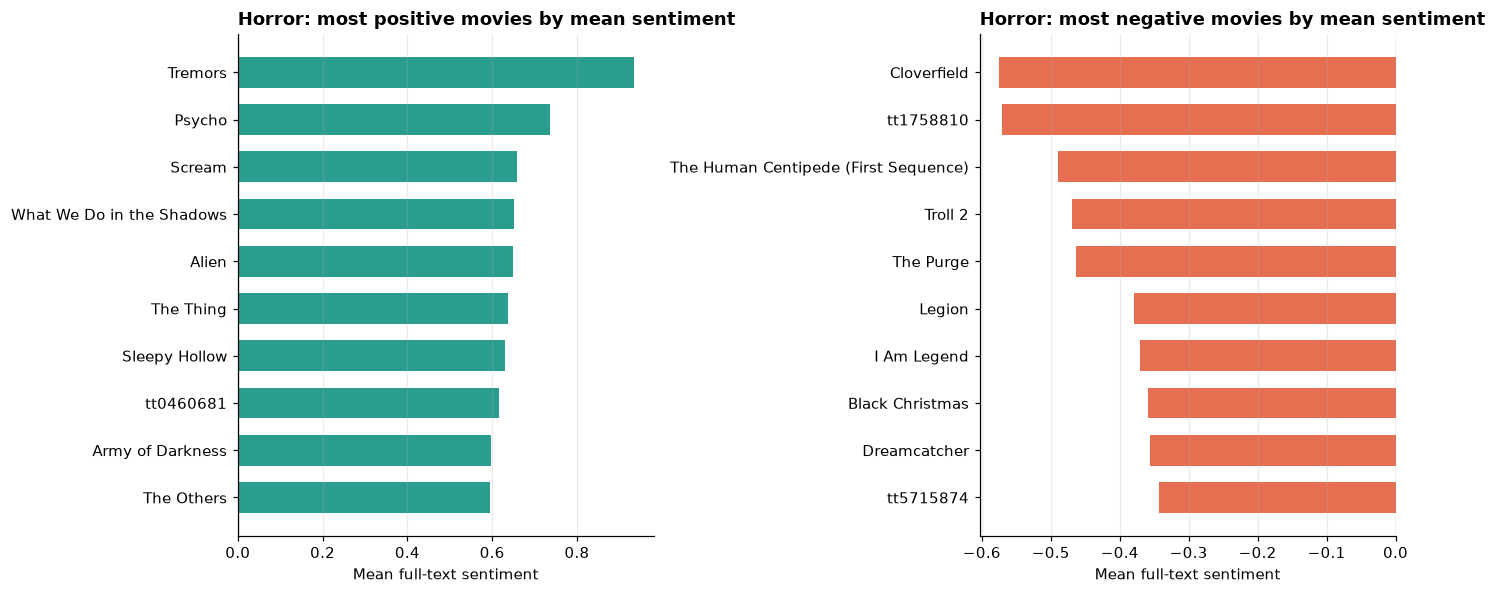

Most polarizing (highest sentiment std):


,title,n,mean_rating,mean_sent,sent_std
108,tt4443658,85,6.07,0.14,0.97
97,Beyond Skyline,55,6.49,0.13,0.96
63,Saw,594,6.40,-0.01,0.96
49,The Cell,464,6.07,0.08,0.96
33,I Know What You Did Last Summer,270,6.23,0.09,0.95
41,Pi,425,6.66,0.14,0.95
107,The Witch,582,5.27,-0.10,0.95
43,End of Days,363,5.78,-0.06,0.95


In [12]:
GENRE = 'Horror'     # change me
MIN_REVIEWS = 50

sub = g[g['genre'] == GENRE]
m = (sub.groupby(['movie_id', 'title'])
        .agg(n=('rating', 'size'), mean_rating=('rating', 'mean'),
             mean_sent=('review_sentiment_score', 'mean'), sent_std=('review_sentiment_score', 'std'))
        .query('n >= @MIN_REVIEWS').reset_index())
print(f'{GENRE}: {len(m)} movies with >= {MIN_REVIEWS} reviews')

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, (title, data, color) in zip(axes, [
        ('Most positive', m.nlargest(10, 'mean_sent').sort_values('mean_sent'), TEAL),
        ('Most negative', m.nsmallest(10, 'mean_sent').sort_values('mean_sent', ascending=False), CORAL)]):
    ax.barh(data['title'], data['mean_sent'], color=color, height=0.65)
    ax.axvline(0, color=GREY, lw=0.8); ax.grid(axis='y', visible=False)
    ax.set_title(f'{GENRE}: {title.lower()} movies by mean sentiment'); ax.set_xlabel('Mean full-text sentiment')
plt.tight_layout(); plt.show()

print('Most polarizing (highest sentiment std):')
m.nlargest(8, 'sent_std')[['title', 'n', 'mean_rating', 'mean_sent', 'sent_std']].round(2)